In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [2]:
df=pd.read_csv('bank.csv')

In [3]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   str    
 2   marital    8743 non-null   str    
 3   education  8885 non-null   str    
 4   default    8908 non-null   str    
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   str    
 7   loan       8882 non-null   str    
 8   contact    8881 non-null   str    
 9   day        8893 non-null   float64
 10  month      8884 non-null   str    
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   str    
 16  deposit    8903 non-null   str    
dtypes: float64(6), int64(1), str(10)
memory usage: 1.2 MB


In [5]:
df.shape

(8912, 17)

In [6]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,8912.000000,8899.000000,8893.000000,8905.000000,8904.000000,8767.000000,8909.000000
mean,41.257855,1539.680638,15.684921,374.953734,2.512579,52.456941,0.834325
std,11.840567,3297.446702,8.406729,351.283501,2.772366,109.094161,2.304733
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.500000,8.000000,139.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,256.000000,2.000000,-1.000000,0.000000
75%,49.000000,1726.000000,22.000000,501.000000,3.000000,64.000000,1.000000
max,95.000000,81204.000000,31.000000,3284.000000,63.000000,842.000000,58.000000


In [7]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'deposit'],
      dtype='str')

In [9]:
df.isnull().sum().sort_values(ascending=False)

marital      169
pdays        145
contact       31
loan          30
month         28
education     27
day           19
balance       13
housing       13
deposit        9
campaign       8
duration       7
job            7
default        4
previous       3
age            0
poutcome       0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df = df.dropna(subset=['deposit','default','previous','campaign','job','duration','contact','housing'])

In [12]:
from sklearn.impute import SimpleImputer

impute = SimpleImputer(strategy='most_frequent')

df[['marital','loan','education','month']] = impute.fit_transform(
    df[['marital','loan','education','month']]
)

In [13]:

impute = SimpleImputer(strategy='mean')

df[['pdays','day','balance']] = impute.fit_transform(
    df[['pdays','day','balance']]
)

In [14]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

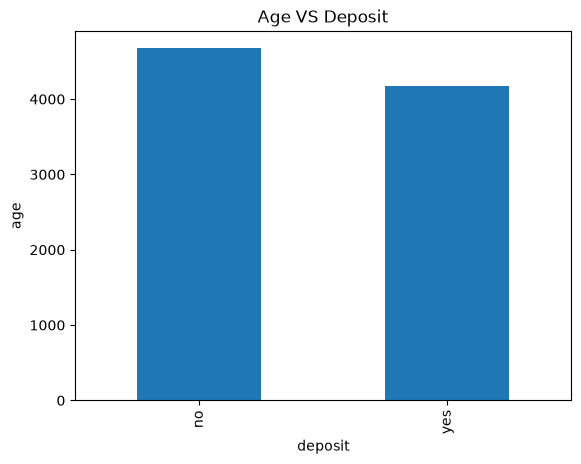

In [15]:
df['deposit'].value_counts().plot(kind='bar')
plt.title('Age VS Deposit')
plt.ylabel('age')
plt.xlabel('deposit')
plt.show()

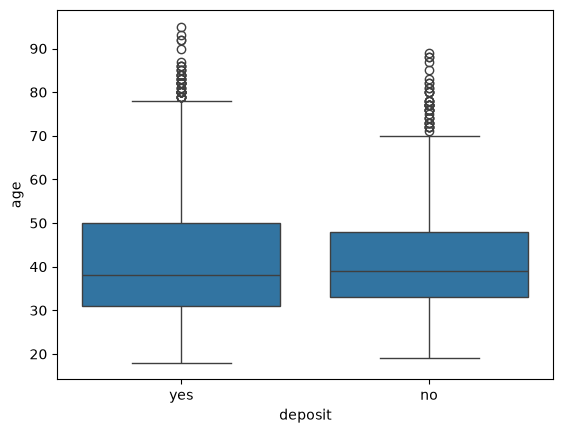

In [16]:
sns.boxplot(data=df, x='deposit', y='age')
plt.show()

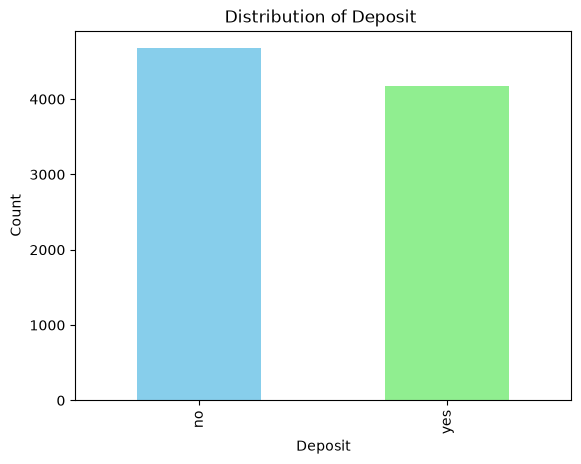

In [17]:
df['deposit'].value_counts().plot(kind='bar', color=['skyblue', 'lightgreen'])
plt.title('Distribution of Deposit ')
plt.ylabel('Count')
plt.xlabel('Deposit')
plt.show()

In [18]:
from sklearn.preprocessing import LabelEncoder

In [19]:
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

C:\Users\PC\AppData\Local\Temp\ipykernel_29308\2528280465.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


In [20]:
X = df.drop(columns=['deposit'])
y = df['deposit']

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [25]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[779 186]
 [183 623]]


c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


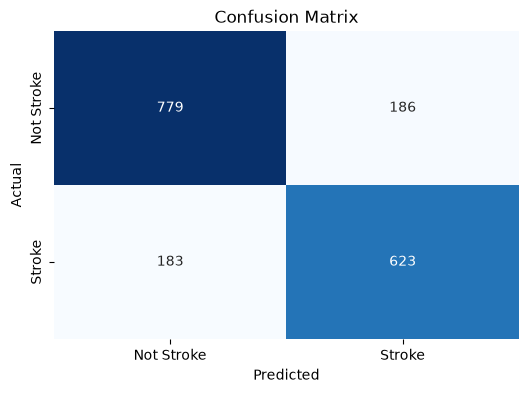


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.81      0.81      0.81       965
      Stroke       0.77      0.77      0.77       806

    accuracy                           0.79      1771
   macro avg       0.79      0.79      0.79      1771
weighted avg       0.79      0.79      0.79      1771

ROC-AUC: 0.8581853713727354


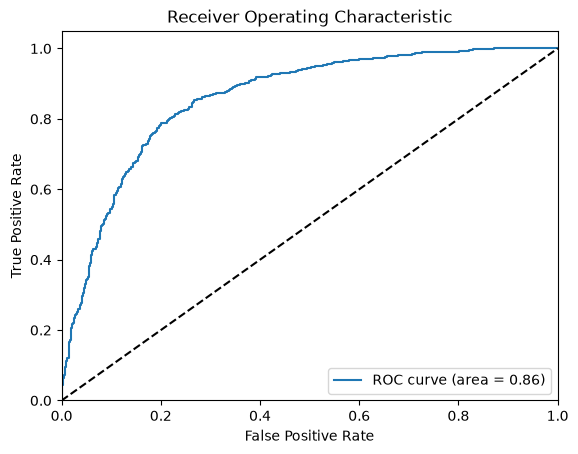

PR AUC: 0.8116710888566048


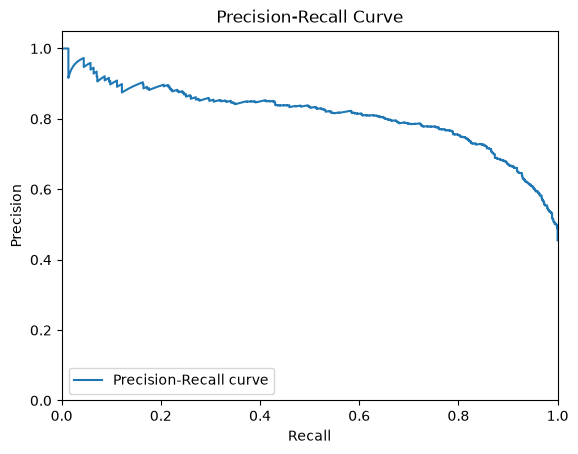

  8%|▊         | 1/13 [00:01<00:15,  1.30s/it]


Confusion Matrix:
 [[743 222]
 [236 570]]


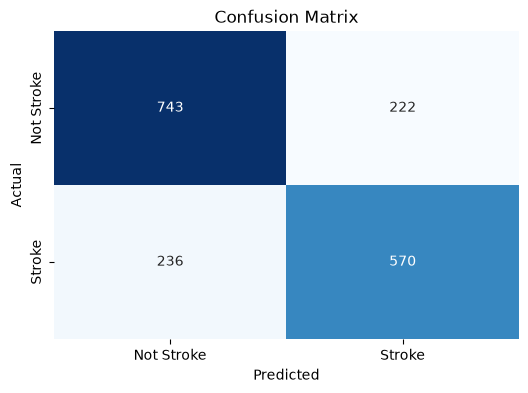


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.76      0.77      0.76       965
      Stroke       0.72      0.71      0.71       806

    accuracy                           0.74      1771
   macro avg       0.74      0.74      0.74      1771
weighted avg       0.74      0.74      0.74      1771

ROC-AUC: 0.7988203756798108


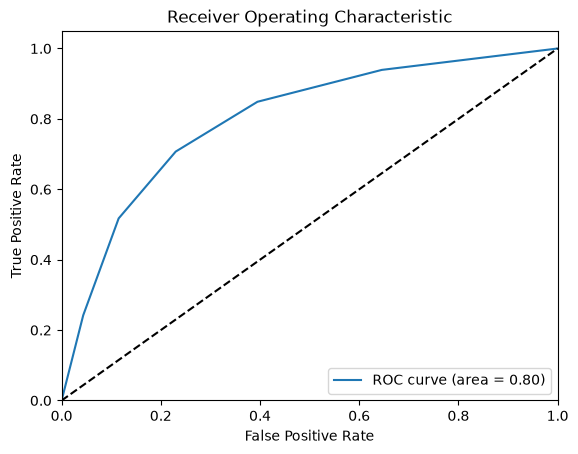

PR AUC: 0.7213991555295085


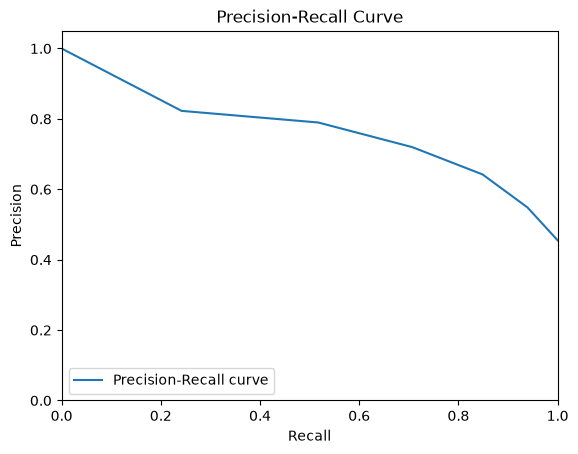

 15%|█▌        | 2/13 [00:03<00:22,  2.05s/it]c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Confusion Matrix:
 [[807 158]
 [308 498]]


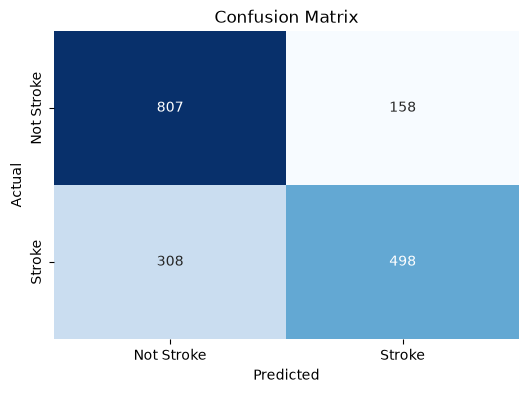


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.72      0.84      0.78       965
      Stroke       0.76      0.62      0.68       806

    accuracy                           0.74      1771
   macro avg       0.74      0.73      0.73      1771
weighted avg       0.74      0.74      0.73      1771

ROC-AUC: 0.8207703878939044


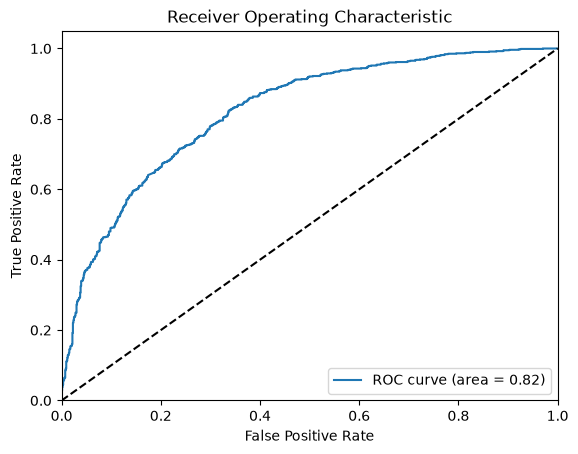

PR AUC: 0.7821476651230759


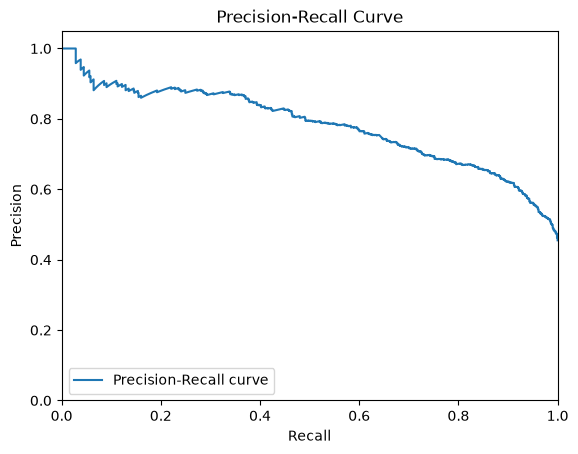

 23%|██▎       | 3/13 [00:13<00:54,  5.46s/it]


Confusion Matrix:
 [[770 195]
 [195 611]]


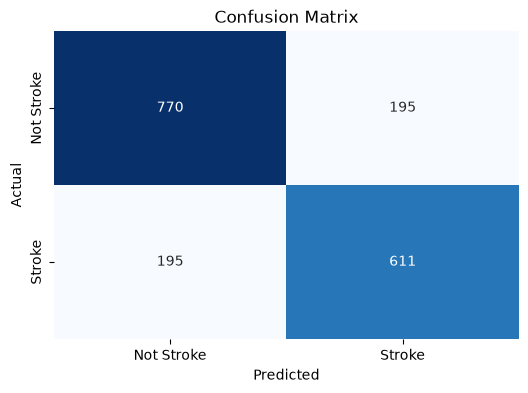


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.80      0.80      0.80       965
      Stroke       0.76      0.76      0.76       806

    accuracy                           0.78      1771
   macro avg       0.78      0.78      0.78      1771
weighted avg       0.78      0.78      0.78      1771

ROC-AUC: 0.7779959886344643


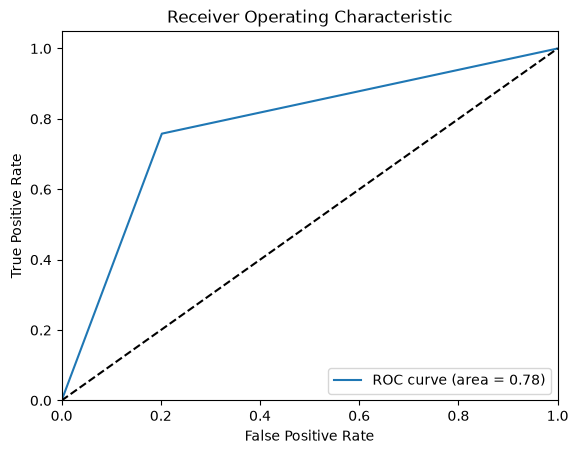

PR AUC: 0.6847690946342714


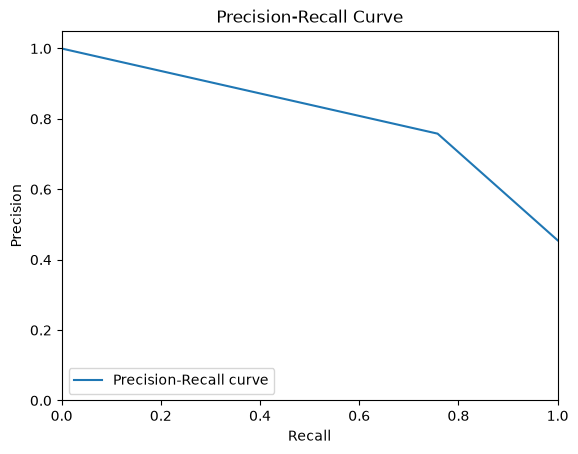

 31%|███       | 4/13 [00:13<00:30,  3.43s/it]


Confusion Matrix:
 [[709 256]
 [182 624]]


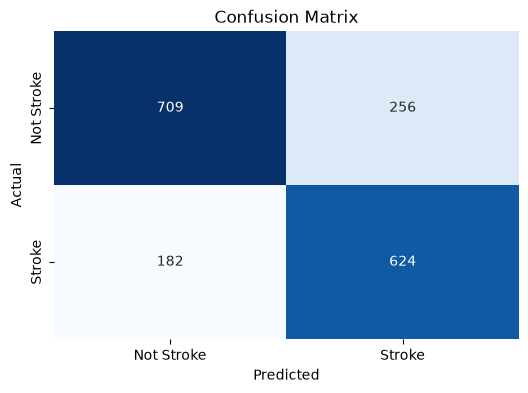


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.80      0.73      0.76       965
      Stroke       0.71      0.77      0.74       806

    accuracy                           0.75      1771
   macro avg       0.75      0.75      0.75      1771
weighted avg       0.76      0.75      0.75      1771

ROC-AUC: 0.8026144589156456


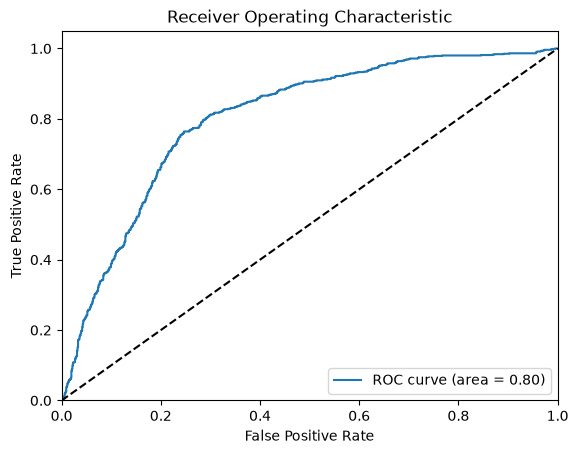

PR AUC: 0.724061244087737


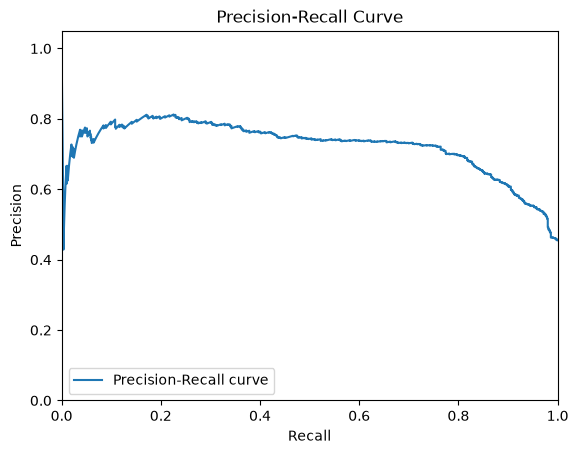

 38%|███▊      | 5/13 [00:14<00:18,  2.31s/it]


Confusion Matrix:
 [[807 158]
 [105 701]]


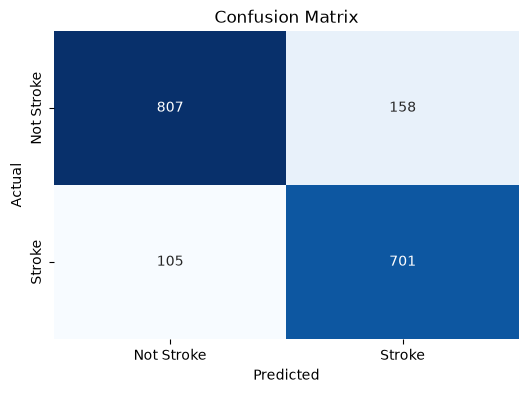


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.84      0.86       965
      Stroke       0.82      0.87      0.84       806

    accuracy                           0.85      1771
   macro avg       0.85      0.85      0.85      1771
weighted avg       0.85      0.85      0.85      1771

ROC-AUC: 0.9189614163206007


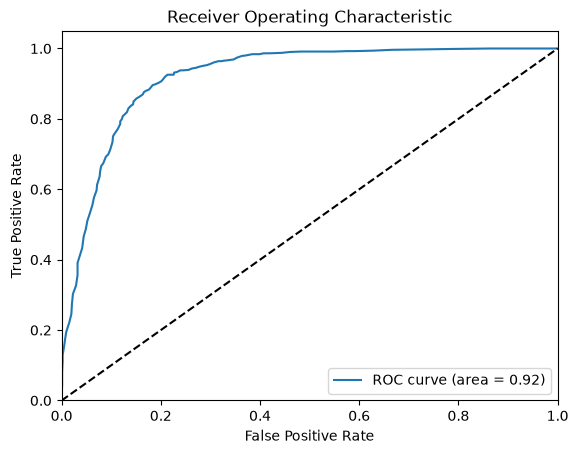

PR AUC: 0.8816645971174545


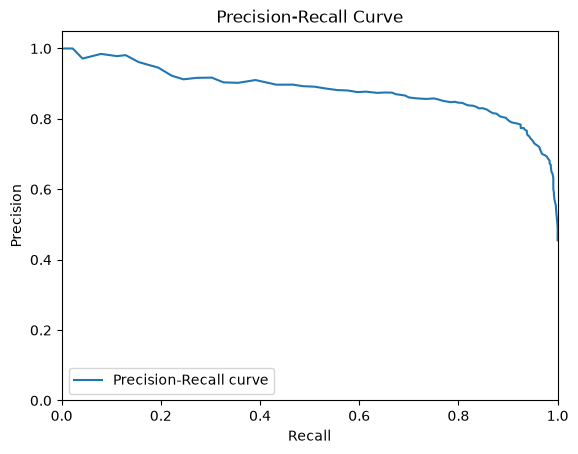

 46%|████▌     | 6/13 [00:15<00:13,  1.90s/it]


Confusion Matrix:
 [[813 152]
 [120 686]]


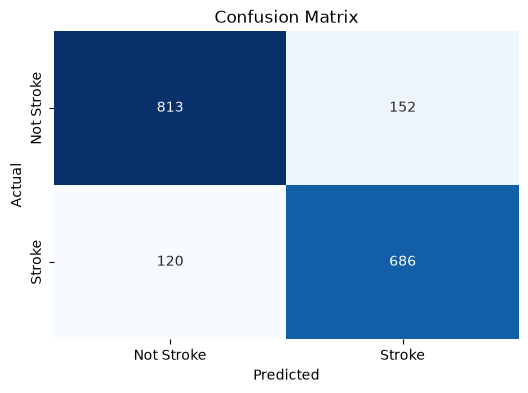


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.84      0.86       965
      Stroke       0.82      0.85      0.83       806

    accuracy                           0.85      1771
   macro avg       0.84      0.85      0.85      1771
weighted avg       0.85      0.85      0.85      1771

ROC-AUC: 0.9154501857827949


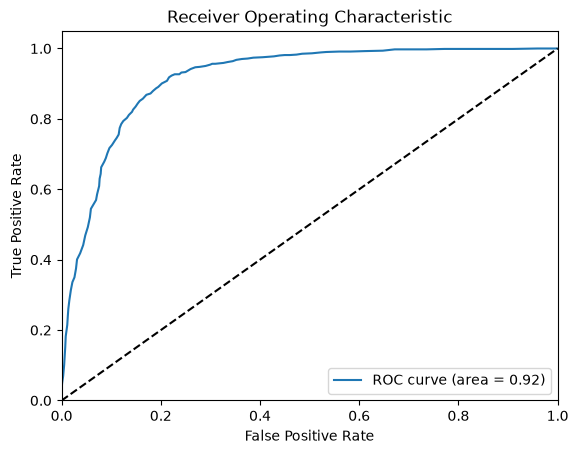

PR AUC: 0.8786228766875821


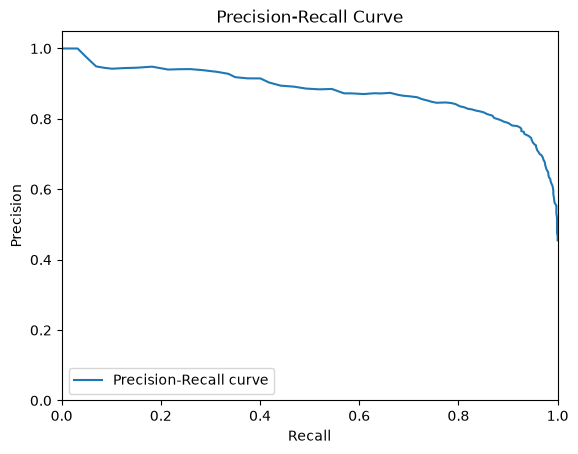

 54%|█████▍    | 7/13 [00:16<00:09,  1.63s/it]


Confusion Matrix:
 [[805 160]
 [171 635]]


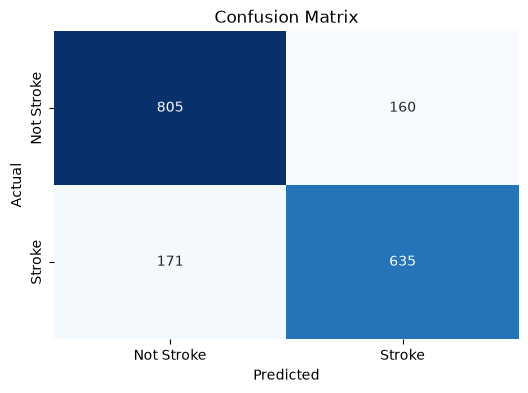


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.82      0.83      0.83       965
      Stroke       0.80      0.79      0.79       806

    accuracy                           0.81      1771
   macro avg       0.81      0.81      0.81      1771
weighted avg       0.81      0.81      0.81      1771

ROC-AUC: 0.8838047544967151


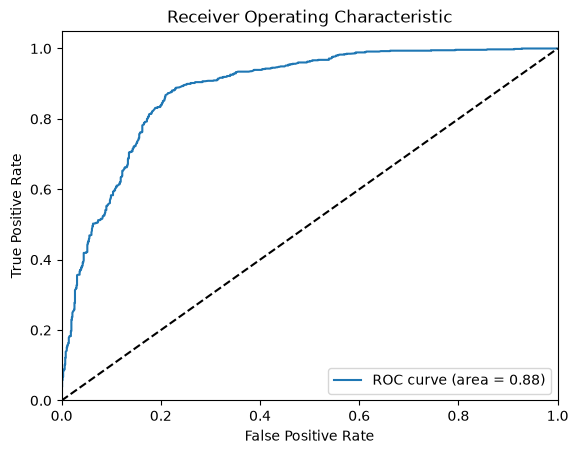

PR AUC: 0.8428101259705227


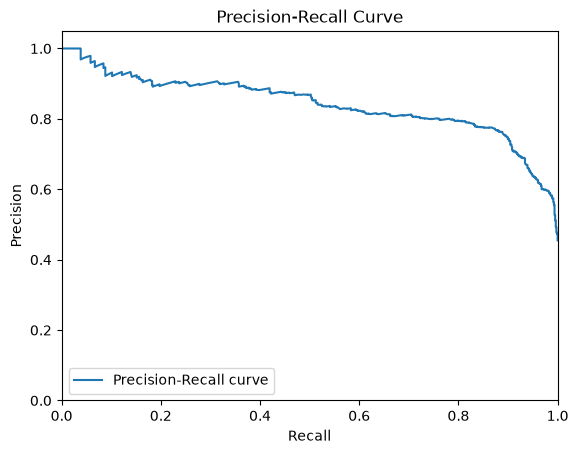

 62%|██████▏   | 8/13 [00:16<00:06,  1.28s/it]


Confusion Matrix:
 [[815 150]
 [116 690]]


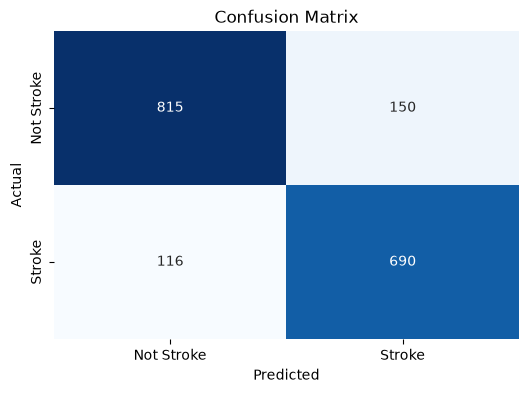


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.84      0.86       965
      Stroke       0.82      0.86      0.84       806

    accuracy                           0.85      1771
   macro avg       0.85      0.85      0.85      1771
weighted avg       0.85      0.85      0.85      1771

ROC-AUC: 0.9194017665436686


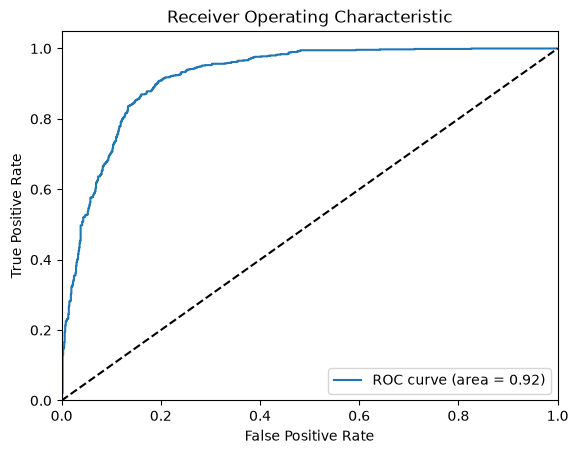

PR AUC: 0.8854533128607879


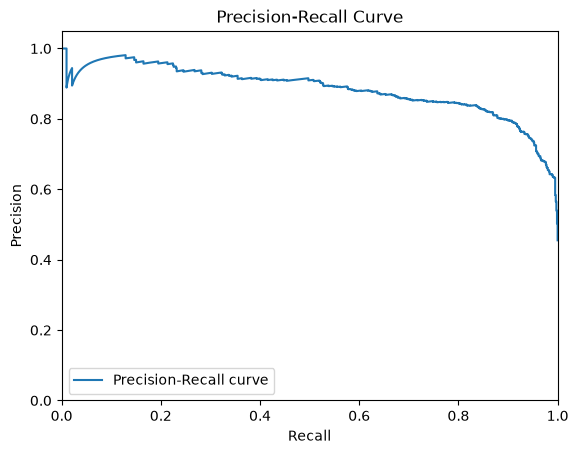

 69%|██████▉   | 9/13 [00:17<00:04,  1.24s/it]


Confusion Matrix:
 [[825 140]
 [ 99 707]]


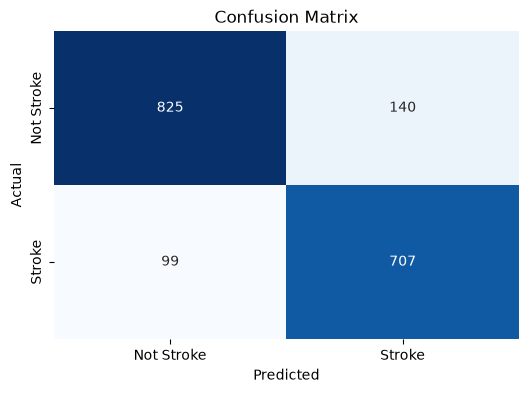


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.85      0.87       965
      Stroke       0.83      0.88      0.86       806

    accuracy                           0.87      1771
   macro avg       0.86      0.87      0.86      1771
weighted avg       0.87      0.87      0.87      1771

ROC-AUC: 0.9327826277015647


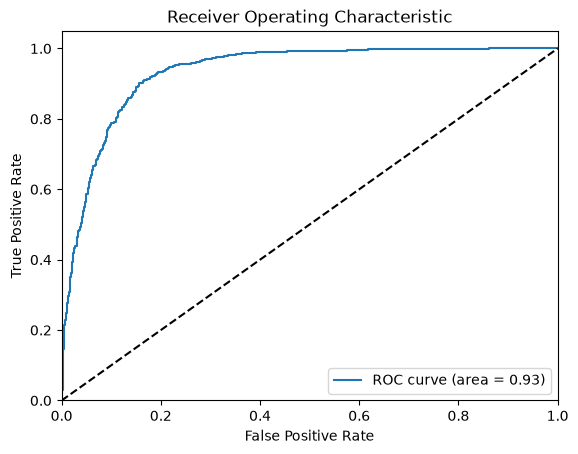

PR AUC: 0.9023620525608369


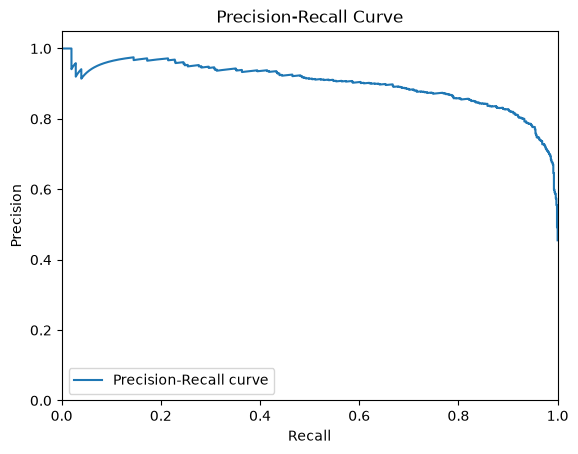

 77%|███████▋  | 10/13 [00:18<00:03,  1.03s/it]c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [15:24:58] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[824 141]
 [105 701]]


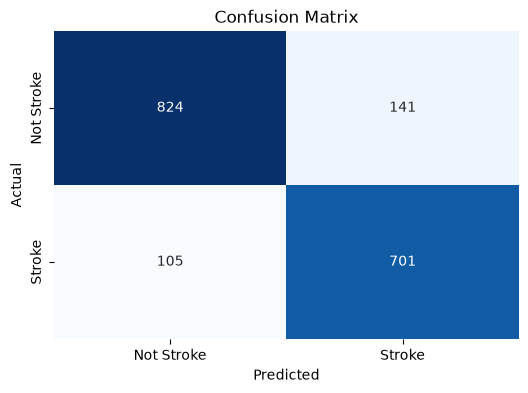


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.85      0.87       965
      Stroke       0.83      0.87      0.85       806

    accuracy                           0.86      1771
   macro avg       0.86      0.86      0.86      1771
weighted avg       0.86      0.86      0.86      1771

ROC-AUC: 0.9276912791370422


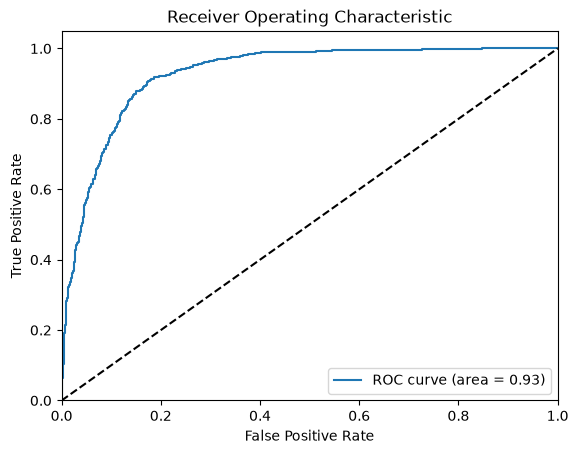

PR AUC: 0.897309731495837


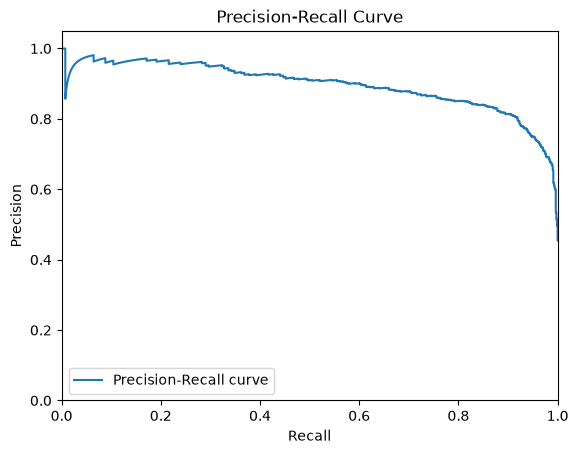

 85%|████████▍ | 11/13 [00:18<00:01,  1.16it/s]


Confusion Matrix:
 [[817 148]
 [105 701]]


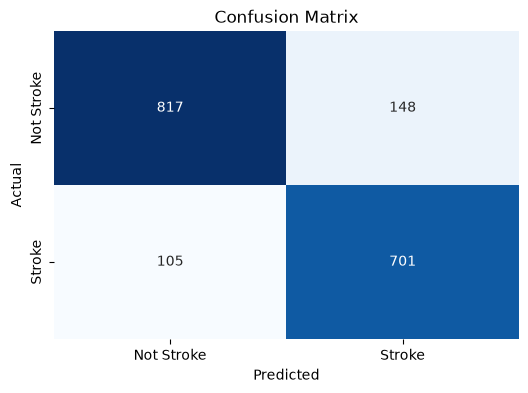


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.85      0.87       965
      Stroke       0.83      0.87      0.85       806

    accuracy                           0.86      1771
   macro avg       0.86      0.86      0.86      1771
weighted avg       0.86      0.86      0.86      1771

ROC-AUC: 0.9322053510587692


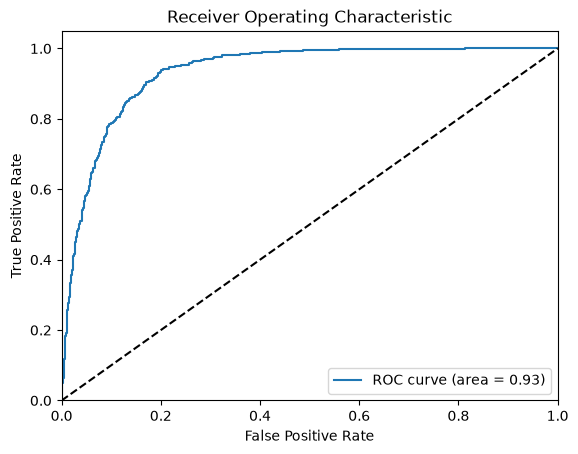

PR AUC: 0.9003222269895329


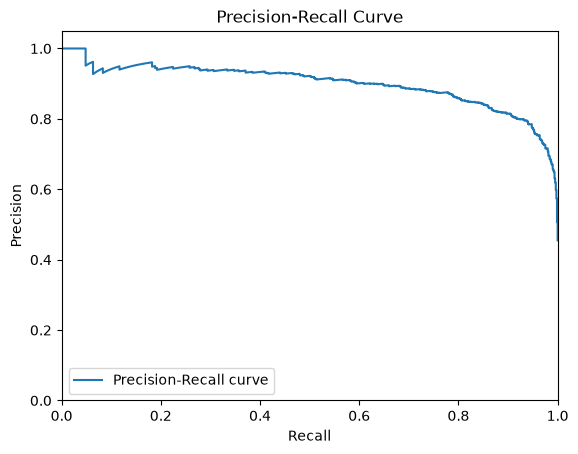

 92%|█████████▏| 12/13 [00:22<00:01,  1.57s/it]

[LightGBM] [Info] Number of positive: 3374, number of negative: 3708
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000762 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 965
[LightGBM] [Info] Number of data points in the train set: 7082, number of used features: 16
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.476419 -> initscore=-0.094394
[LightGBM] [Info] Start training from score -0.094394

Confusion Matrix:
 [[820 145]
 [ 90 716]]


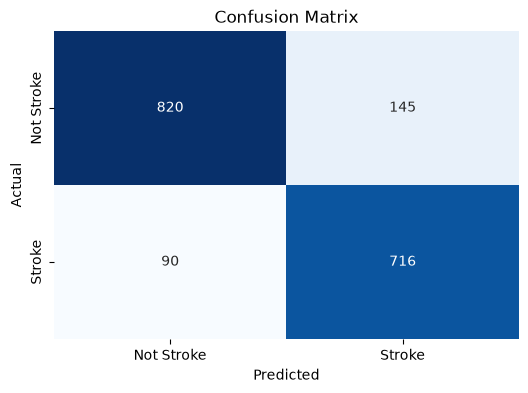


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.90      0.85      0.87       965
      Stroke       0.83      0.89      0.86       806

    accuracy                           0.87      1771
   macro avg       0.87      0.87      0.87      1771
weighted avg       0.87      0.87      0.87      1771

ROC-AUC: 0.9332107638308541


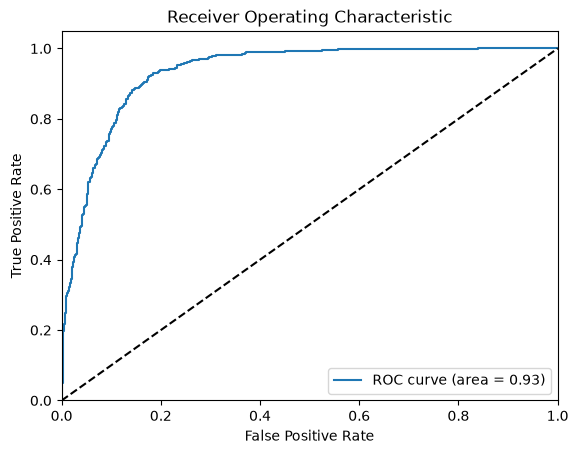

PR AUC: 0.9043325619397615


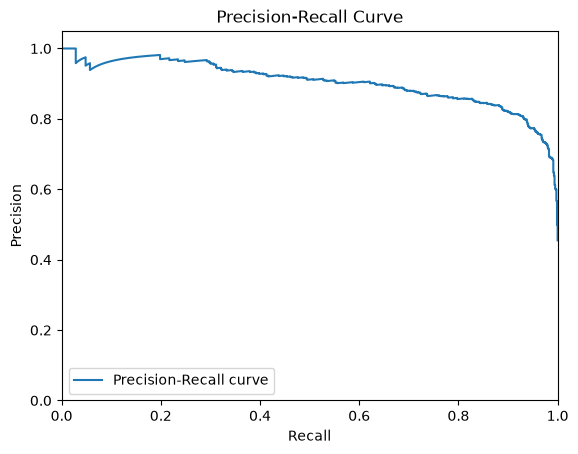

100%|██████████| 13/13 [00:22<00:00,  1.73s/it]


In [26]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)
    
    

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--') 
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    

In [29]:
results_df = pd.DataFrame(results).T
display(results_df)

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Logistic Regression,0.794408,0.791643,0.787470,0.770087,0.778601,0.772953,0.783010,0.771517,0.793696,0.790103,0.858185,0.811671
KNN,0.818130,0.741389,0.810232,0.719697,0.807350,0.707196,0.808789,0.713392,0.817645,0.738572,0.798820,0.721399
SVC,0.738210,0.736872,0.774765,0.759146,0.635151,0.617866,0.698046,0.681259,0.733568,0.727068,0.820770,0.782148
Decision Tree,1.000000,0.779785,1.000000,0.758065,1.000000,0.758065,1.000000,0.758065,1.000000,0.777996,0.777996,0.684769
Naive Bayes,0.750071,0.752682,0.720209,0.709091,0.777416,0.774194,0.747719,0.740214,0.751302,0.754454,0.802614,0.724061
Random Forest,1.000000,0.851496,1.000000,0.816065,1.000000,0.869727,1.000000,0.842042,1.000000,0.852998,0.918961,0.881665
Extra Trees,1.000000,0.846414,1.000000,0.818616,1.000000,0.851117,1.000000,0.834550,1.000000,0.846802,0.915450,0.878623
AdaBoost,0.813894,0.813100,0.810199,0.798742,0.795791,0.787841,0.802931,0.793254,0.813079,0.811019,0.883805,0.842810
Gradient Boosting,0.861056,0.849802,0.839875,0.821429,0.875222,0.856079,0.857184,0.838396,0.861694,0.850319,0.919402,0.885453
Hist Gradient Boosting,0.921209,0.865048,0.893956,0.834711,0.946947,0.877171,0.919689,0.855414,0.922368,0.866047,0.932783,0.902362
